# Background

## DNA replication
DNA replication is the process of copying chromosomes before cell division, ensuring that each daughter cell receives a complete copy of the genome. Replication begins at loci called **replication origins**, well-defined sequences recognized by initiator proteins. Helicase unwinds and separates the double-stranded DNA in order for DNA polymerase to start synthesizing new strands. 

Because DNA strands are antiparallel and DNA polymerase can synthesize only in the 5′→3′ direction, replication proceeds differently on each strand:

1.   **The leading strand** is synthesized continuously toward the replication fork.
2.   **The lagging strand** is synthesized discontinuously in short segments called Okazaki fragments, later joined by DNA ligase.

![](https://media.springernature.com/full/springer-static/image/art%3A10.1038%2F439542a/MediaObjects/41586_2006_Article_BF439542a_Fig1_HTML.jpg)

## Bacterial genome
Bacterial genomes typically consist of a single **circular chromosome**, though some species may have multiple chromosomes or additional small, circular DNA molecules known as plasmids. These often carry genes that provide advantages, such as antibiotic resistance or metabolic capabilities, but are not essential for basic survival.

<div style="max-width:1000px;margin-right: auto; margin-right: 0;">
    
![](https://www.sciencelearn.org.nz/_next/image?url=https%3A%2F%2Fwww.datocms-assets.com%2F117510%2F1722387675-enzymes_bacterialdna.jpg%3Fw%3D1840%26h%3D920&w=1920&q=85)
    
</div>

In bacteria, DNA replication only has one origin, known as **oriC**. It then usually proceeds bidirectionally from oriC until the two forks meet at the **termination region**, completing the circular chromosome.

## GC skew
The **GC skew** is a genomic measure that reflects the imbalance between guanine and cytosine nucleotides along DNA strands. It is commonly defined (informally) for a given one-stranded DNA segment as **(G − C) / (G + C)**, where G (C) stands for the number of guanine (cytosine) in this segment. A more formal definition of the GC skew in segment $S$ would be $$\text{GC skew} = \frac{N_G-N_C}{N_G+N_C},\qquad\text{where }N_A = \sum_{X\text{ in }S}\delta_{AX},$$ where $X\in\{A,T,G,C\}$ are the nucleotides (and $\delta_{ij}$ is the Kronecker delta).

The origin of the GC skew is not fully agreed upon, but it is thought to be connected to differences in mutation rates on the leading and lagging DNA strands. During replication, the leading strand remains single-stranded while the DNA polymerase works, while the lagging strand is protected by Okazaki fragments. Single-stranded DNA is prone to deamination of cytosine to thymine, leading to the leading strand being enriched for G (and T, a phenomenon known as AT skew). In many bacterial genomes, the GC skew changes sign at the **origin** and **terminus of replication**, making it an indicator for locating these regions. 

# Exercises

## Exercise 1: Investigate GC skew in bacterial genomes

1. Download the following bacterial genomes from NCBI:

| Species                  | RefSeq Accession |
|---------------------------|------------------|
| *Escherichia coli*        | NC_000913.3      |
| *Bacillus subtilis*       | NC_000964.3      |
| *Staphylococcus aureus*   | NC_007795.1      |
| *Pseudomonas aeruginosa*  | NC_002516.2      |

An example for E. coli is given below. 

2. Write a function that takes a DNA sequence and outputs its GC skew. Test it on the following example sequences, and consider carefully what the output should be: 
- `seq = 'GGGCCC'`
- `seq = 'GGGGAAAA'`
- `seq = 'CCCCCTTT'`
- `seq = 'TTAAA'`

3. Write a function to compute the local GC skew across a genome with a sliding window approach. This function should take arguments for the window length and the step size between successive windows, and it should output two lists: one for the starting positions of the sliding window along the genome and another for the corresponding GC-skews.

4. Apply this function to the four genomes you downloaded, experimenting with various window sizes and step sizes, and visualise the results. Justify the final window and step sizes you landed on. What tradeoffs did you have to optimise? 

5. An alternative approach to visualising the GC skew is using the cumulative skew, that is, adding $+1$ for each G, and substracting $-1$ for each C you find along the genome. Implement this function, and visualise the results for each of the four genomes. 

In [1]:
from Bio import Entrez, SeqIO

def fetch_request(refseq_id):
    with Entrez.efetch(db="nucleotide", id=refseq_id, rettype="fasta", retmode="text") as handle:
        record = SeqIO.read(handle, "fasta")
    return record.seq

e_coli = fetch_request("NC_000913.3")
bacillus_subtilis = fetch_request("NC_000964.3")
staphylococcus_aureus = fetch_request("NC_007795.1")
pseudomonas_aeruginosa = fetch_request("NC_002516.2")


c:\Users\ferdi\AppData\Local\Programs\Python\Python312\Lib\site-packages\Bio\Entrez\__init__.py:693: UserWarning: 
            Email address is not specified.

            To make use of NCBI's E-utilities, NCBI requires you to specify your
            email address with each request.  As an example, if your email address
            is A.N.Other@example.com, you can specify it as follows:
               from Bio import Entrez
               Entrez.email = 'A.N.Other@example.com'
            In case of excessive usage of the E-utilities, NCBI will attempt to contact
            a user at the email address provided before blocking access to the
            E-utilities.
  warnings.warn(


In [2]:
from Bio.Seq import Seq
import math

def gc_skew(seq : Seq):
    ng = seq.count("G")
    nc = seq.count("C")
    if ng + nc == 0:
        return math.nan
    return (ng - nc) / (ng + nc)

examples = ['GGGCCC', 'GGGGAAAA', 'CCCCCTTT', 'TTAAA']
print("Examples:")
for example in examples:
    print(f"{example:<10}: GC skeq {gc_skew(Seq(example))}")
print()

print(f"E-Coli: {gc_skew(e_coli):.4f}")
print(f"bacillus_subtilis: {gc_skew(bacillus_subtilis):.4f}")
print(f"staphylococcus_aureus: {gc_skew(staphylococcus_aureus):.4f}")
print(f"pseudomonas_aeruginosa: {gc_skew(pseudomonas_aeruginosa):.4f}")


Examples:
GGGCCC    : GC skeq 0.0
GGGGAAAA  : GC skeq 1.0
CCCCCTTT  : GC skeq -1.0
TTAAA     : GC skeq nan

E-Coli: -0.0011
bacillus_subtilis: -0.0023
staphylococcus_aureus: -0.0047
pseudomonas_aeruginosa: -0.0086


In [3]:
def sliding_gc_skew(seq: Seq, window_size, step_size):
    start_positions = []
    gc_skews = []
    for start in range(0, len(seq) - window_size + 1, step_size):
        seq.count
        ng = seq[start : start + window_size].count("G")
        nc = seq[start : start + window_size].count("C")
        start_positions.append(start)
        if ng + nc == 0:
            gc_skews.append(0)
        else:
            gc_skews.append((ng - nc) / (ng + nc))
    return start_positions, gc_skews

[]

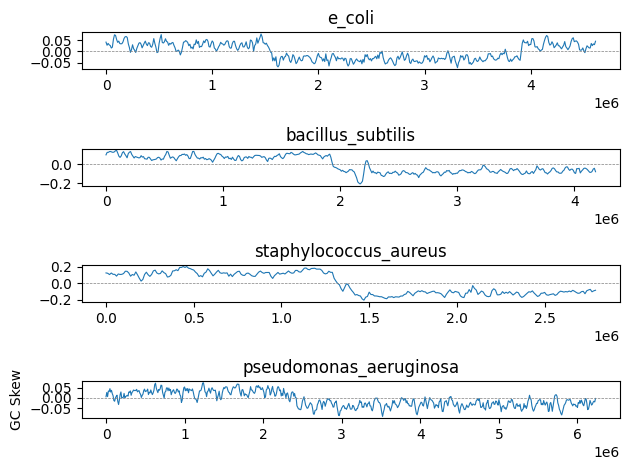

In [4]:
import matplotlib.pyplot as plt

window_size = 30_000
step_size = 10_000

genomes = [e_coli, bacillus_subtilis, staphylococcus_aureus, pseudomonas_aeruginosa]
names = ["e_coli", "bacillus_subtilis", "staphylococcus_aureus", "pseudomonas_aeruginosa"]
fig, axes = plt.subplots(len(genomes), 1)
for i in range(len(genomes)):
    ax = axes[i]
    seq = genomes[i]
    name = names[i]
    start_pos, gc_skew = sliding_gc_skew(seq, window_size, step_size)
    ax.plot(start_pos, gc_skew, lw=0.8)
    ax.axhline(0, color="gray", lw=0.5, ls="--")
    ax.set_title(name)
plt.ylabel("GC Skew")
fig.tight_layout()
plt.plot()

[]

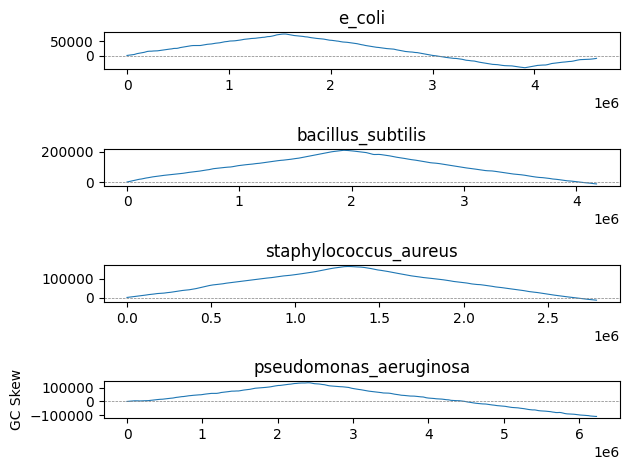

In [5]:
def cum_gc_skew(seq, step_size):
    cum_value = 0
    start_positions = []
    gc_skews = []
    for start in range(0, len(seq) - window_size + 1, step_size):
        seq.count
        ng = seq[start : start + window_size].count("G")
        nc = seq[start : start + window_size].count("C")
        cum_value += ng
        cum_value -= nc
        start_positions.append(start)
        gc_skews.append(cum_value)
    return start_positions, gc_skews

step_size = 10_000

genomes = [e_coli, bacillus_subtilis, staphylococcus_aureus, pseudomonas_aeruginosa]
names = ["e_coli", "bacillus_subtilis", "staphylococcus_aureus", "pseudomonas_aeruginosa"]
fig, axes = plt.subplots(len(genomes), 1)
for i in range(len(genomes)):
    ax = axes[i]
    seq = genomes[i]
    name = names[i]
    start_pos, gc_skew = cum_gc_skew(seq, step_size)
    ax.plot(start_pos, gc_skew, lw=0.8)
    ax.axhline(0, color="gray", lw=0.5, ls="--")
    ax.set_title(name)
plt.ylabel("GC Skew")
fig.tight_layout()
plt.plot()

## Exercise 2: Assembly by hand

Assume that the following reads have been sequenced without any errors:
- r0 = `AAGTGA`,
- r1 = `TGAATA`,
- r2 = `ATATATA`,
- r3 = `TATAGCCA`,
- r4 = `GCCAATA`,
- r5 = `ATAGGGC`,
- r6 = `GGGCATA`.

Answer the following questions without using computational tools.  

a) For every pair of reads (ri, rj), determine the corresponding overlap length (i.e. the maximal length of a suffix of ri that exactly matches a prefix of rj).

b) Separately construct (directed) overlap graphs with overlap lengths ≥ 2, ≥ 3, and ≥ 4, respectively.

c) For every graph in b), determine all Hamiltonian paths.

d) Which minimal overlap length is the best choice for the construction of a reference genome (for the given read set {r0, . . . , r6})?

e) For your choice in d), determine a corresponding reference genome sequence for each Hamiltonian path.

f) What would be required to resolve potential ambiguities?

## Exercise 3: Assembly using computers
Solve exercises a-c from Exercise 2 using python. Use  `networkx` for graph visualisation. 

Overlap lengths
           AAGTGA     TGAATA     ATATATA    TATAGCCA   GCCAATA    ATAGGGC    GGGCATA   
    AAGTGA:     -         3         1         0         0         1         0     
    TGAATA:     1         -         3         2         0         3         0     
   ATATATA:     1         0         -         4         0         3         0     
  TATAGCCA:     1         0         1         -         4         1         0     
   GCCAATA:     1         0         3         2         -         3         0     
   ATAGGGC:     0         0         0         0         2         -         4     
   GGGCATA:     1         0         3         2         0         3         -     


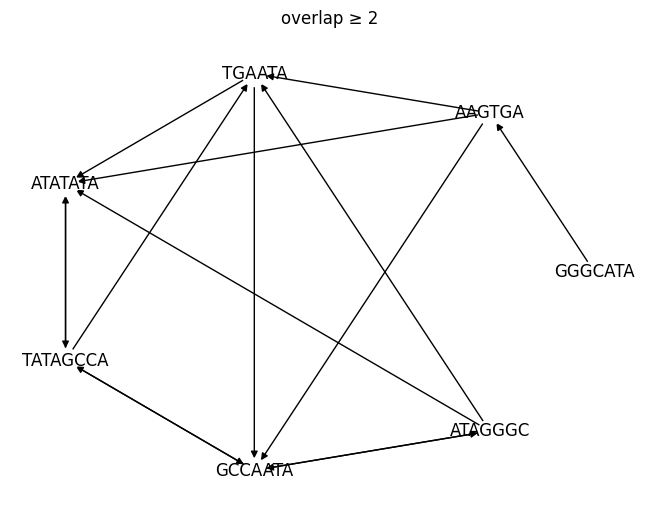

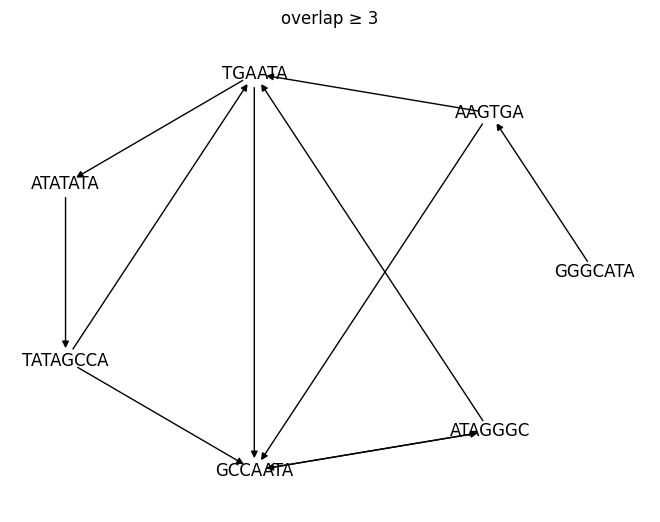

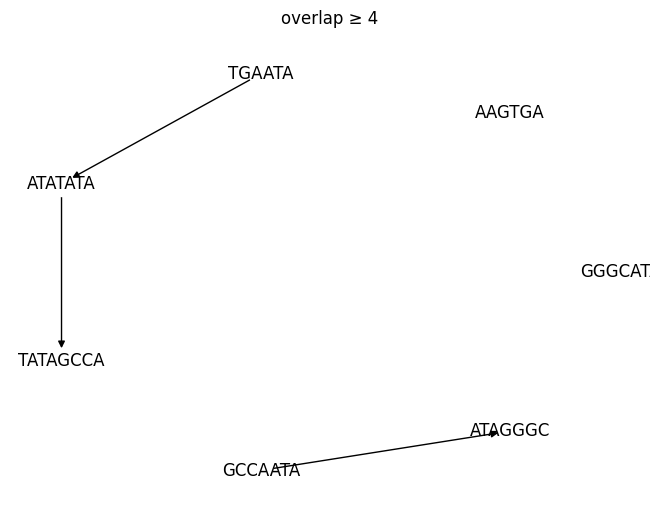

2: Number of hamiltonian paths: 6
['GGGCATA', 'AAGTGA', 'ATATATA', 'TATAGCCA', 'GCCAATA', 'ATAGGGC', 'TGAATA']
['GGGCATA', 'AAGTGA', 'GCCAATA', 'ATAGGGC', 'ATATATA', 'TATAGCCA', 'TGAATA']
['GGGCATA', 'AAGTGA', 'TGAATA', 'GCCAATA', 'ATAGGGC', 'ATATATA', 'TATAGCCA']
['GGGCATA', 'AAGTGA', 'GCCAATA', 'ATAGGGC', 'TGAATA', 'ATATATA', 'TATAGCCA']
['GGGCATA', 'AAGTGA', 'TGAATA', 'ATATATA', 'TATAGCCA', 'GCCAATA', 'ATAGGGC']
['GGGCATA', 'AAGTGA', 'ATATATA', 'TATAGCCA', 'TGAATA', 'GCCAATA', 'ATAGGGC']
3: Number of hamiltonian paths: 2
['GGGCATA', 'AAGTGA', 'GCCAATA', 'ATAGGGC', 'TGAATA', 'ATATATA', 'TATAGCCA']
['GGGCATA', 'AAGTGA', 'TGAATA', 'ATATATA', 'TATAGCCA', 'GCCAATA', 'ATAGGGC']
4: Number of hamiltonian paths: 0


In [7]:
import networkx as nx

reads = ["AAGTGA", "TGAATA", "ATATATA", "TATAGCCA", "GCCAATA", "ATAGGGC", "GGGCATA"]

def overlap(a, b):
    for k in range(min(len(a), len(b)), 0, -1):
        if a[-k:] == b[:k]:
            return k
    return 0

print("Overlap lengths")
n = len(reads)
print(" ".join(f"{read:<10}" for read in ["", *reads]))
ov = dict()
for k in range(len(reads)):
    read1 = reads[k]
    line = f"{read1:>10}: "
    for j in range(len(reads)):
        if j == k:
            line += f"{"-":^10}"
            continue
        line += f"{overlap(read1, reads[j]):^10}"
        ov[(k, j)] = overlap(read1, reads[j])
    print(line)




def overlap_graph(min_len):
    G = nx.DiGraph()
    G.add_nodes_from(range(n))
    for (i, j), k in ov.items():
        if k >= min_len:
            G.add_edge(i, j, weight=k)
    return G

for k in [2, 3, 4]:
    G = overlap_graph(k)
    pos = nx.circular_layout(G)
    labels = {i: f"{reads[i-1]}" for i in G.nodes}
    nx.draw(G, pos, labels=labels, node_color="white")
    plt.title(f"overlap ≥ {k}")
    plt.show()





def hamiltonian_paths(G):
    paths = []
    for s in G.nodes:
        for t in G.nodes:
            if s == t:
                continue
            for p in nx.all_simple_paths(G, s, t):
                if len(p) == G.number_of_nodes():
                    paths.append(p)
    return paths

for i in [2, 3, 4]:
    G = overlap_graph(i)
    h_paths = hamiltonian_paths(G)
    print(f"{i}: Number of hamiltonian paths: {len(h_paths)}")
    for path in h_paths:
        print(f"{[reads[n - 1] for n in path]}")